In [1]:
import numpy as onp
import matplotlib.pyplot as plt
from jax import numpy as np
from vmc_core import *
# from vmc_core import RNG

In [2]:
# for nu, nd in [(1,1), (2,2), (3,3), (6,6)]:
#     print(f"N_up={nu}, N_down={nd} | orbitals={occupied_orbitals(nu)} | E0={exact_energy(nu,nd)}")
# assert [exact_energy(n,n) for n in (1,2,3,6)] == [2,6,10,28]

In [3]:
# # Same-spin swap: one minus sign, no change in |psi|².
# X_test = RNG.normal(size=(20,6,2))
# X_swapped = X_test.copy()
# X_swapped[:,[0,1],:] = X_test[:,[1,0],:]
# a_test = RNG.normal(size=len(S_K))   # nonzero Jastrow: it must be symmetric under the swap too
# l1 = logpsi(X_test, a_test, 3)
# l2 = logpsi(X_swapped, a_test, 3)
# onp.testing.assert_allclose(l2, l1, atol=1e-12)
# s1 = np.linalg.slogdet(build_slaters(X_test, 3)[0])[0]
# s2 = np.linalg.slogdet(build_slaters(X_swapped, 3)[0])[0]
# onp.testing.assert_array_equal(s2, -s1)
# print("Same-spin exchange: sign flips and |psi|² is unchanged.")

In [4]:
# sweep_step = 5   # Metropolis steps between recorded samples: set it to about the tau printed below
# n_samples = 5000 # recorded samples per chain
# runs = {}        # (nu,nd) -> dictionary of results returned by sample_mcmc
# autocorr = {}
# # for nu,nd in [(1,1),(2,2),(3,1)]:
# for nu,nd in [(4,4)]:
#     res = sample_mcmc(logpsi, n_particles=nu + nd, n_samples=n_samples, n_discard=400, step_size=1.1, n_up=nu, n_chains=200,
#                       sweep_step=sweep_step, measures=("energy", "V", "density", "acceptance"))
#     runs[(nu,nd)] = res
#     e, err, sigma = res["energy"]["mean"], res["energy"]["error"], res["energy"]["sigma"]
#     V = res["V"]
#     expected = exact_energy(nu,nd)
#     print(f'{nu}+{nd}: VMC E={e[-1]:.12f} ± {err[-1]:.2g} | exact={expected} | '
#           f'acceptance={res["acceptance"]:.3f} | std of E_L={sigma[-1]:.2g}')
#     assert onp.abs(e[-1]-expected)<1e-10

#     autocorr[(nu,nd)] = autocorrelation(V)
#     tau = autocorrelation_time(autocorr[(nu,nd)])
#     print(f'{nu}+{nd}: autocorrelation time tau = {tau:.1f} recorded samples '
#           f'(sweep_step={sweep_step}) -> effective samples per chain ~ {len(V)/tau:.0f}')

In [5]:
# # Running mean vs iteration
# # E_L is constant for an exact eigenstate, so its running mean sits on E from the start and does not test the sampler.
# # Virial theorem (harmonic trap): <V> = <T> = E/2, so 2<V> -> E only if the samples are really distributed as |psi|^2
# fig, ax = plt.subplots(figsize=(6.6,3.7))
# for k, ((nu,nd), res) in enumerate(runs.items()):
#     V = res["V"]
#     it = onp.arange(1, len(V) + 1)
#     # running mean of each chain separately; the chains are independent, so the spread between them
#     # gives an honest error bar even though samples inside one chain are correlated
#     run_chain = onp.cumsum(V, axis=0) / it[:, None]             # shape (n_samples, n_chains)
#     mean = run_chain.mean(axis=1)
#     err = run_chain.std(axis=1, ddof=1) / onp.sqrt(run_chain.shape[1])
#     ax.plot(it, mean, color=f'C{k}', label=f'{nu}+{nd}: running mean of $V$')
#     ax.fill_between(it, mean - err, mean + err, color=f'C{k}', alpha=0.25, lw=0)
#     ax.axhline(exact_energy(nu,nd)/2, color=f'C{k}', ls='--', lw=0.8)
# ax.set(xlabel='Iteration (recorded sample)', ylabel='Running mean', title='Convergence to the expec. val. of V (dashed)')
# ax.legend(frameon=False, fontsize=8)
# plt.show()

In [6]:
# # Radial density: VMC histogram (error bars from the spread of the chains) and exact n(r), both integrate to N
# # n_exact is the angular average for the 4+4 filling, so it is only drawn for that one
# fig, ax = plt.subplots(figsize=(6.6,3.7))
# for k, ((nu,nd), res) in enumerate(runs.items()):
#     r, density, err = density_from_hist(res["density"]["hist"], res["density"]["edges"], n_samples)
#     ax.errorbar(r, density, yerr=err, fmt='.', ms=5, lw=0.8, color=f'C{k}', label=f'{nu}+{nd}: VMC')
#     if (nu,nd) == (4,4):
#         ax.plot(r, n_exact(r), color='k', lw=1, zorder=3, label=f'{nu}+{nd}: exact')
# ax.set(xlabel='$r$', ylabel='$n(r)$ (particles per unit area)', title='Radial density')
# ax.legend(frameon=False, fontsize=8)
# plt.show()

## Stage 2: interacting VMC
$\Psi = D_\uparrow D_\downarrow\, e^J$ with $V(r)=-V_0\,\mathrm{sech}^2(r/R_0)$ between opposite spins.
`logpsi` is the single determinant, `logpsi_paired` the paired state $\sum_{p=x,y}D_\uparrow[\varphi_0,\varphi_p]\,D_\downarrow[\varphi_0,\varphi_p]\,e^J$ (only for 2+2).

In [14]:
# With a_k = 0 and V0 = 0 we must recover Stage 1 exactly: E_L = E0 at every configuration (zero variance),
# so we check it pointwise on random configurations, no sampling needed (only round-off, larger close to a node of psi).
# The paired state too: both terms are eigenstates with the same E0 = 6, so their sum is one as well.
a0 = onp.zeros(len(S_K))
# Z_test = np.asarray(onp.random.default_rng(0).normal(size=(100, 6, 2)))
# for (nu, nd), lp in [((1,1), logpsi), ((2,1), logpsi), ((2,2), logpsi), ((3,3), logpsi), ((2,2), logpsi_paired)]:
#     EL = local_energy(Z_test[:, :nu+nd], a0, nu, 0.0, lp)
#     print(f"{nu}+{nd} {lp.__name__:13s}: E0={exact_energy(nu, nd)}, max|E_L - E0| = {np.max(np.abs(EL - exact_energy(nu, nd))):.1e}")
#     assert np.allclose(EL, exact_energy(nu, nd), rtol=0, atol=1e-6)

EB=0.3: V0=53.053212, E_free=-0.300000, E2_trapped=0.978623
EB=1.0: V0=67.377015, E_free=-1.000000, E2_trapped=0.140232
EB=2.5: V0=84.028080, E_free=-2.500000, E2_trapped=-1.431455


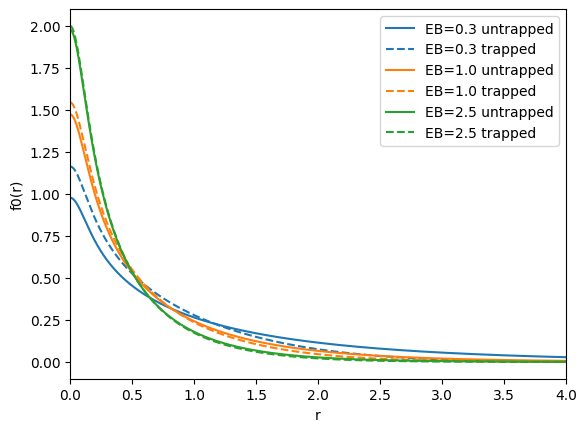

E_B=0.3: single det E=4.981 ± 0.009 | paired E=4.905 ± 0.009 | paired - single = -0.076 ± 0.012
E_B=1.0: single det E=4.719 ± 0.011 | paired E=4.592 ± 0.011 | paired - single = -0.126 ± 0.015
E_B=2.5: single det E=4.436 ± 0.013 | paired E=4.270 ± 0.014 | paired - single = -0.166 ± 0.019


In [8]:
# N=4 (2+2), interacting, a_k = 0: single determinant vs paired state at the three couplings.
# Both have E0 = 6, so E = 6 + <V_int>: the difference is only in how often opposite spins meet.
# The narrow, deep well makes E_L very noisy (std ~5), so we use many short chains (cheap, they are vectorized).
import two_body                      # importing runs the two-body solver: two_body.results[E_B] = (V0, E2, f_free, f_trap)
E_N4 = {}                            # (E_B, wavefunction name) -> (E, error)
for EB, (V0, *_) in two_body.results.items():
    for lp in (logpsi, logpsi_paired):
        res = sample_mcmc(lp, n_particles=4, n_samples=400, n_discard=100, step_size=0.7, n_up=2, n_chains=4000,
                          params=a0, V0=V0, progress=False)
        E_N4[EB, lp.__name__] = res["energy"]["mean"][-1], res["energy"]["error"][-1]
    (e1, d1), (e2, d2) = E_N4[EB, "logpsi"], E_N4[EB, "logpsi_paired"]
    print(f"E_B={EB}: single det E={e1:.3f} ± {d1:.3f} | paired E={e2:.3f} ± {d2:.3f} | "
          f"paired - single = {e2-e1:.3f} ± {onp.hypot(d1, d2):.3f}")

**Cross-check (first order, contact limit $R_0\to0$).** At $a_k=0$: $E \simeq 6 + g\int\rho_{\uparrow\downarrow}(\mathbf R,\mathbf R)\,d^2R$, with $g=\int V\,d^2r=-2\pi\ln2\,R_0^2V_0$.
Single determinant: $\rho_{\uparrow\downarrow}=(\varphi_0^2+\varphi_x^2)^2$, integral $11/8\pi$. Paired state: $\rho_{\uparrow\downarrow}=e^{-2R^2}(1+2R^2+2R^4)/\pi^2$, integral $3/2\pi$.
The paired state puts more opposite-spin weight at contact, so it is lower by $g/8\pi$:

| $E_B$ | single det | paired | paired − single |
|---|---|---|---|
| 0.3 | 4.989 | 4.897 | −0.092 |
| 1.0 | 4.716 | 4.599 | −0.117 |
| 2.5 | 4.398 | 4.253 | −0.146 |

### Optimized Jastrow: $N=2$, then $N=3,4,6$ from the $N=2$ parameters
At every coupling: optimize the $a_k$ (`optimize_jastrow`), then one long run at the optimized $a_k$ for $E$ and $P_{\uparrow\downarrow}(r)$.
For $N=4$ the single determinant and the paired state each get their own optimized Jastrow.

In [9]:
# N=2 starts from a_k = 0, N=3,4,6 from the N=2 parameters of the same coupling.
# n_chains=1000 per iteration: with fewer, the gradient for N>2 is so noisy that a Newton step can jump to a much worse a_k.
# Takes ~8 minutes.
systems = {"N=2": (logpsi, 2, 1), "N=3": (logpsi, 3, 2), "N=4": (logpsi, 4, 2), "N=4 paired": (logpsi_paired, 4, 2), "N=6": (logpsi, 6, 3)}
opt = {}                             # (E_B, system) -> optimized a_k, E, error of E, (r, P_updown)
for EB, (V0, *_) in two_body.results.items():
    for name, (lp, N, nu) in systems.items():
        a, _ = optimize_jastrow(lp, N, nu, V0, params=None if name == "N=2" else opt[EB, "N=2"]["a"], n_chains=1000)
        res = sample_mcmc(lp, N, n_samples=400, n_discard=100, step_size=0.5, n_up=nu, n_chains=4000, params=a, V0=V0,
                          measures=("energy", "pair"), progress=False)
        opt[EB, name] = dict(a=a, E=res["energy"]["mean"][-1], err=res["energy"]["error"][-1], pair=res["pair"])

optimization: 100%|██████████| 30/30 [00:23<00:00,  1.25it/s]


In [10]:
# Tables for the meeting: E_2 VMC vs exact, and N=4 single determinant vs paired state (each with its own optimized Jastrow)
print("E_2: VMC vs exact")
for EB, (V0, E2, *_) in two_body.results.items():
    o = opt[EB, "N=2"]
    print(f"  E_B={EB}: VMC {o['E']:.5f} ± {o['err']:.5f} | exact {E2:.5f} | VMC - exact = {o['E'] - E2:+.5f}")
    assert abs(o["E"] - E2) < 1e-3
print("N=4: single determinant vs paired state")
for EB in two_body.results:
    s, p = opt[EB, "N=4"], opt[EB, "N=4 paired"]
    print(f"  E_B={EB}: single det {s['E']:.3f} ± {s['err']:.3f} | paired {p['E']:.3f} ± {p['err']:.3f} | "
          f"paired - single = {p['E'] - s['E']:.3f} ± {onp.hypot(s['err'], p['err']):.3f}")

E_2: VMC vs exact
  E_B=0.3: VMC 0.97869 ± 0.00008 | exact 0.97862 | VMC - exact = +0.00007
  E_B=1.0: VMC 0.14029 ± 0.00012 | exact 0.14023 | VMC - exact = +0.00005
  E_B=2.5: VMC -1.43160 ± 0.00017 | exact -1.43146 | VMC - exact = -0.00015
N=4: single determinant vs paired state
  E_B=0.3: single det 3.682 ± 0.003 | paired 3.427 ± 0.003 | paired - single = -0.255 ± 0.005
  E_B=1.0: single det 2.135 ± 0.007 | paired 1.703 ± 0.006 | paired - single = -0.432 ± 0.009
  E_B=2.5: single det -0.569 ± 0.014 | paired -1.276 ± 0.012 | paired - single = -0.707 ± 0.018


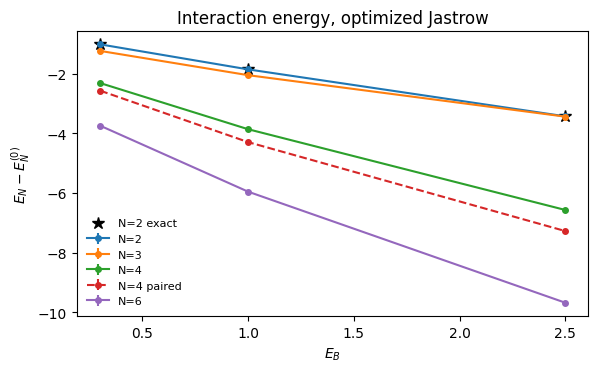

In [11]:
# E_N - E_N^(0) vs E_B (E_N^(0): non-interacting energy), stars: exact E_2 - 2
EBs = list(two_body.results)
fig, ax = plt.subplots(figsize=(6.6, 3.7))
for name, (lp, N, nu) in systems.items():
    ax.errorbar(EBs, [opt[EB, name]["E"] - exact_energy(nu, N - nu) for EB in EBs], yerr=[opt[EB, name]["err"] for EB in EBs],
                marker='o', ms=4, ls='--' if 'paired' in name else '-', label=name)
ax.plot(EBs, [two_body.results[EB][1] - 2 for EB in EBs], 'k*', ms=9, label='N=2 exact')
ax.set(xlabel='$E_B$', ylabel='$E_N - E_N^{(0)}$', title='Interaction energy, optimized Jastrow')
ax.legend(frameon=False, fontsize=8)
plt.show()

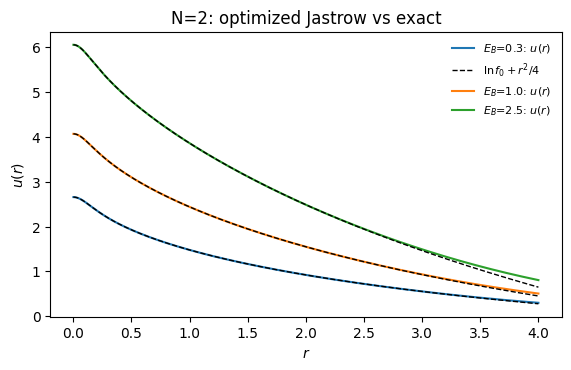

In [12]:
# N=2: the exact wavefunction is phi_cm(R) f_0(r) = phi_0(r_1) phi_0(r_2) e^{ln f_0(r) + r^2/4}, so the ideal u is
# ln f_0 + r^2/4 up to a constant (it only changes the normalization): we shift it to match u on average, weighted by |f_0|^2
r = two_body.r[two_body.r < 4]
fig, ax = plt.subplots(figsize=(6.6, 3.7))
for k, (EB, (V0, E2, f_free, f0)) in enumerate(two_body.results.items()):
    u = onp.exp(-r[:, None]**2 / (2 * S_K**2)) @ opt[EB, "N=2"]["a"]
    u_exact = onp.log(f0[:len(r)]) + r**2 / 4
    u_exact += onp.average(u - u_exact, weights=r * f0[:len(r)]**2)
    ax.plot(r, u, color=f'C{k}', label=f'$E_B$={EB}: $u(r)$')
    ax.plot(r, u_exact, 'k--', lw=1, label=r'$\ln f_0 + r^2/4$' if k == 0 else None)
ax.set(xlabel='$r$', ylabel='$u(r)$', title='N=2: optimized Jastrow vs exact')
ax.legend(frameon=False, fontsize=8)
plt.show()

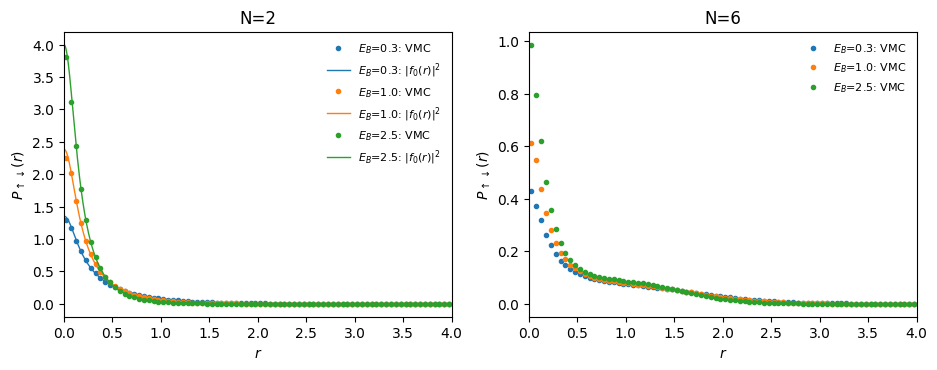

In [13]:
# Opposite-spin pair distribution, per pair (integral over d^2r = 1): N=2 with the exact |f_0(r)|^2, and N=6
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7))
for k, (EB, (V0, E2, f_free, f0)) in enumerate(two_body.results.items()):
    for ax, name in zip(axs, ("N=2", "N=6")):
        r, P = opt[EB, name]["pair"]
        ax.plot(r, P, '.', color=f'C{k}', label=f'$E_B$={EB}: VMC')
    axs[0].plot(two_body.r, f0**2, color=f'C{k}', lw=1, label=f'$E_B$={EB}: $|f_0(r)|^2$')
for ax, name in zip(axs, ("N=2", "N=6")):
    ax.set(xlim=(0, 4), xlabel='$r$', ylabel=r'$P_{\uparrow\downarrow}(r)$', title=name)
    ax.legend(frameon=False, fontsize=8)
plt.show()